# **Projet : Prédiction d'une maladie cardiovasculaire**

## **I - Introduction**

**L'objectif de ce projet est de développer des modèles de classification permettant de prédire la présence ou l'absence d'une pathologie cardiaque chez un patient à partir de ses caractéristiques cliniques.**

Pour ce faire, nous exploiterons un jeu de données médicales comprenant notamment les caractéristiques cliniques et les antécédents des patients, afin d'estimer la probabilité de présence d'une maladie cardiovasculaire. 

Après une étape de sélection des variables visant à ne conserver que les caractéristiques discrètes, nous mettrons en œuvre deux modèles d'apprentissage supervisé : un **classifieur bayésien naïf de Bernoulli** et un **perceptron multicouche (MLP)**. Enfin, une **analyse comparative de leurs performances prédictives** permettra d'évaluer l'efficacité de chaque approche et d'identifier le modèle le plus adapté à cette tâche de classification.

### Dictionnaire des données


$$
\begin{array}{|l|l|}
\hline
\textbf{Nom de la colonne} & \textbf{Description} \\
\hline
\text{GOAL-Heart Disease} & \text{Indique si le patient souffre d'une maladie cardiovasculaire} \\
\hline
\text{Age (years)} & \text{Âge du patient en années} \\
\hline
\text{Sex} & \text{Sexe du patient (par ex., 'Homme' ou 'Femme')} \\
\hline
\text{Chest Pain type} & \text{Type de douleur thoracique ressentie par le patient} \\
\hline
\text{Resting blood pressure (mm/Hg)} & \text{Pression artérielle au repos en millimètres de mercure (mm/Hg)} \\
\hline
\text{Serum cholesterol (mg/dl)} & \text{Taux de cholestérol sérique en milligrammes par décilitre (mg/dl)} \\
\hline
\text{Fasting blood pressure (>120mg/dl)} & \text{Indique si la glycémie à jeun est supérieure à 120 mg/dl ('Oui' ou 'Non')} \\
\hline
\text{Resting ECG results} & \text{Résultat de l'électrocardiogramme au repos} \\
\hline
\text{Maximum heart rate achieved} & \text{Fréquence cardiaque maximale atteinte par le patient lors d'un exercice physique} \\
\hline
\text{Exercise induced angina} & \text{Indique si le patient ressent de l'angine provoquée par l'exercice} \\
\hline
\text{ST depression induced by exercise} & \text{Niveau de dépression du segment ST sur un ECG pendant l'exercice} \\
\hline
\text{Slope of the ST segment} & \text{Pente du segment ST sur un ECG pendant ou après l'exercice} \\
\hline
\text{Number of major vessels colored by flourosopy} & \text{Nombre de vaisseaux majeurs visibles sur une fluoroscopie} \\
\hline
\text{Thalassemia} & \text{Type de thalassémie (trouble sanguin)} \\
\hline
\end{array}
$$

## Import des librairies

In [2]:
import numpy as np                # créer et manipuler des tableaux de données multidimensionnels
import pandas as pd               # Pour l'analyse et la manipulation des données
import matplotlib.pyplot as plt   # Pour la data visualization
import seaborn as sns             # Pour la data visualization

from sklearn.model_selection import train_test_split      # Pour séparer les données
from sklearn.preprocessing import OneHotEncoder           # Pour encoder les variables
from sklearn.naive_bayes import BernoulliNB               # Pour Bernoulli
from sklearn.neural_network import MLPClassifier          # Pour le perceptron 
from sklearn.model_selection import GridSearchCV          # Hyperparamètres
from sklearn.metrics import (accuracy_score, classification_report, precision_score, recall_score, f1_score, ConfusionMatrixDisplay)

## **II - Chargement des données**

In [3]:
# Chargeons et affichons nos données
data = pd.read_csv("/workspaces/Cardiovascular-Disease-Prediction/data/Cardiovascular Disease Prediction.csv", sep = ";")
data.head(8)

,GOAL-Heart Disease,Age (years),Sex,Chest Pain type,Resting blood pressure (mm/Hg),Serum cholesterol (mg/dl),Fasting blood pressure (>120mg/dl),Resting ECG results,Maximum heart rate achieved,Exercise induced angina,ST depression induced by exercise,Slope of the ST segment,Number of major vessels colored by flourosopy,Thalassemia
0,Yes,63,Male,Typical angina,145,233,Yes,Left ventricular hypertrophy,150,No,2.3,Downsloping,0,fixed defect
1,No,37,Male,Non-anginal pain,130,250,No,Normal,187,No,3.5,Downsloping,0,normal
2,Yes,41,Female,Atypical angina,130,204,No,Left ventricular hypertrophy,172,No,1.4,Upsloping,0,normal
3,Yes,56,Male,Atypical angina,120,236,No,Normal,178,No,0.8,Upsloping,0,normal
4,No,57,Female,Asymptomatic,120,354,No,Normal,163,Yes,0.6,Upsloping,0,normal
5,Yes,57,Male,Asymptomatic,140,192,No,Normal,148,No,0.4,Flat,0,fixed defect
6,Yes,56,Female,Atypical angina,140,294,No,Left ventricular hypertrophy,153,No,1.3,Flat,0,normal
7,Yes,44,Male,Atypical angina,120,263,No,Normal,173,No,0.0,Upsloping,0,reversable defect


## **III - Analyse exploratoire des données (AED)**

### 1. Inspection basique

In [4]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column                                         Non-Null Count  Dtype  
---  ------                                         --------------  -----  
 0   GOAL-Heart Disease                             303 non-null    str    
 1   Age (years)                                    303 non-null    int64  
 2   Sex                                            303 non-null    str    
 3   Chest Pain type                                303 non-null    str    
 4   Resting blood pressure (mm/Hg)                 303 non-null    int64  
 5   Serum cholesterol (mg/dl)                      303 non-null    int64  
 6   Fasting blood pressure (>120mg/dl)             303 non-null    str    
 7   Resting ECG results                            303 non-null    str    
 8   Maximum heart rate achieved                    303 non-null    int64  
 9   Exercise induced angina                        303 non-null    st

In [5]:
#Vérification des valeurs manquantes
data.isna().sum()

GOAL-Heart Disease                               0
Age (years)                                      0
Sex                                              0
Chest Pain type                                  0
Resting blood pressure (mm/Hg)                   0
Serum cholesterol (mg/dl)                        0
Fasting blood pressure (>120mg/dl)               0
Resting ECG results                              0
Maximum heart rate achieved                      0
Exercise induced angina                          0
ST depression induced by exercise                0
Slope of the ST segment                          0
Number of major vessels colored by flourosopy    0
Thalassemia                                      0
dtype: int64

In [6]:
nb_doublons = data.duplicated().sum()
print(f"Nombre de lignes totalement identiques : {nb_doublons}")

Nombre de lignes totalement identiques : 1


In [7]:
# Affichons toutes les lignes impliquées
toutes_occurrences = data[data.duplicated(keep=False)]
toutes_occurrences

,GOAL-Heart Disease,Age (years),Sex,Chest Pain type,Resting blood pressure (mm/Hg),Serum cholesterol (mg/dl),Fasting blood pressure (>120mg/dl),Resting ECG results,Maximum heart rate achieved,Exercise induced angina,ST depression induced by exercise,Slope of the ST segment,Number of major vessels colored by flourosopy,Thalassemia
163,Yes,38,Male,Non-anginal pain,138,175,No,Normal,173,No,0.0,Upsloping,4,normal
164,Yes,38,Male,Non-anginal pain,138,175,No,Normal,173,No,0.0,Upsloping,4,normal


In [8]:
data_clean = data.drop_duplicates()

In [9]:
data_clean.info()

<class 'pandas.DataFrame'>
Index: 302 entries, 0 to 302
Data columns (total 14 columns):
 #   Column                                         Non-Null Count  Dtype  
---  ------                                         --------------  -----  
 0   GOAL-Heart Disease                             302 non-null    str    
 1   Age (years)                                    302 non-null    int64  
 2   Sex                                            302 non-null    str    
 3   Chest Pain type                                302 non-null    str    
 4   Resting blood pressure (mm/Hg)                 302 non-null    int64  
 5   Serum cholesterol (mg/dl)                      302 non-null    int64  
 6   Fasting blood pressure (>120mg/dl)             302 non-null    str    
 7   Resting ECG results                            302 non-null    str    
 8   Maximum heart rate achieved                    302 non-null    int64  
 9   Exercise induced angina                        302 non-null    str    

Notre dataset (clean) est constitué de 302 lignes (nombre d'observations) et 14 colonnes (caractéristiques de chaque patient + variable cible). On constate que nous n'avons pas de valeurs manquantes et cela pour chacun des 302 patients de notre étude. Nos données sont de 3 types : **float64, int64 et str.**

In [10]:
# Examinons les valeurs uniques pour chaque colonne.
for i in data_clean.columns:
    print(i, data_clean[i].unique())
    print()  # Ajoute une ligne vide

GOAL-Heart Disease <StringArray>
['Yes', 'No']
Length: 2, dtype: str

Age (years) [63 37 41 56 57 44 52 54 48 49 64 58 50 66 43 69 59 42 61 40 71 51 65 53
 46 45 39 47 62 34 35 29 55 60 67 68 74 76 70 38 77]

Sex <StringArray>
['Male', 'Female']
Length: 2, dtype: str

Chest Pain type <StringArray>
['Typical angina', 'Non-anginal pain', 'Atypical angina', 'Asymptomatic']
Length: 4, dtype: str

Resting blood pressure (mm/Hg) [145 130 120 140 172 150 110 135 160 105 125 142 155 104 138 128 108 134
 122 115 118 100 124  94 112 102 152 101 132 148 178 129 180 136 126 106
 156 170 146 117 200 165 174 192 144 123 154 114 164]

Serum cholesterol (mg/dl) [233 250 204 236 354 192 294 263 199 168 239 275 266 211 283 219 340 226
 247 234 243 302 212 175 417 197 198 177 273 213 304 232 269 360 308 245
 208 264 321 325 235 257 216 256 231 141 252 201 222 260 182 303 265 309
 186 203 183 220 209 258 227 261 221 205 240 318 298 564 277 214 248 255
 207 223 288 160 394 315 246 244 270 195 196 254 126 3

### 2. Analyse descriptive des variables

Avant de sélectionner les variables qui serviront à l'entraînement des modèles, nous allons examiner leur distribution et identifier les éventuels déséquilibres.

#### 2.1. Analyse de la variable cible

In [11]:
# Distribution de la variable cible
effectifs = data_clean["GOAL-Heart Disease"].value_counts()
proportions = data_clean["GOAL-Heart Disease"].value_counts(normalize=True) * 100

print("Effectifs :")
print(effectifs)

Effectifs :
GOAL-Heart Disease
Yes    164
No     138
Name: count, dtype: int64


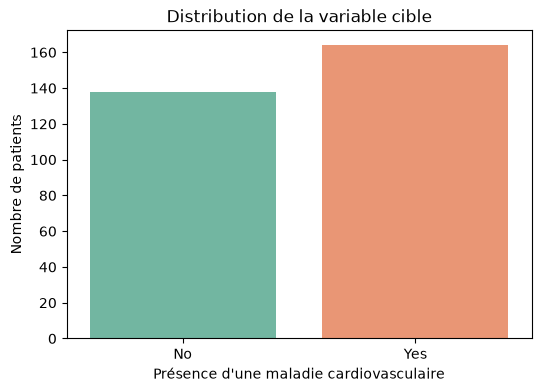

GOAL-Heart Disease
Yes    54.304636
No     45.695364
Name: proportion, dtype: float64


In [14]:
plt.figure(figsize=(6, 4))
sns.countplot(data=data_clean, x="GOAL-Heart Disease", order=["No", "Yes"], hue="GOAL-Heart Disease",
    palette={"No": "#66c2a5", "Yes": "#fc8d62"}, legend=False )

plt.title("Distribution de la variable cible")
plt.xlabel("Présence d'une maladie cardiovasculaire")
plt.ylabel("Nombre de patients")
plt.show()
print(data_clean['GOAL-Heart Disease'].value_counts(normalize=True) * 100)

Cette analyse permet d'examiner la répartition des patients selon la présence ou l'absence d'une maladie cardiovasculaire. 
Il était important de vérifier si les deux classes sont relativement équilibrées, car un déséquilibre important pourrait influencer l'entraînement et l'évaluation de nos modèles de classification.

#### 2.2. Identification des variables discrètes

Conformément à l'objectif de notre projet, nous allons conserver uniquement les variables discrètes.

Il faut toutefois distinguer deux types de variables :
- > **Variables qualitatives (ou catégorielles)** : elles décrivent des catégories, des étiquettes ou des attributs non numériques, par exemple le sexe ou les résultats de l'ECG.
- > **Variables quantitatives (ou numériques)** : elles représentent des mesures ou des comptes sur lesquels des opérations mathématiques ont du sens, par exemple l'âge.

On va conserver les **7 variables qualitatives** ainsi que la **variable quantitative discrète pure**, et écarter les **5 variables quantitatives continues**.

In [36]:
# Sélection des variables discrètes
variables_discretes = [
    "Sex",
    "Chest Pain type",
    "Fasting blood pressure (>120mg/dl)",
    "Resting ECG results",
    "Exercise induced angina",
    "Slope of the ST segment",
    "Number of major vessels colored by flourosopy",
    "Thalassemia"
]

target = "GOAL-Heart Disease"
data_discrete = data_clean[variables_discretes + [target]].copy()
data_discrete.head()

,Sex,Chest Pain type,Fasting blood pressure (>120mg/dl),Resting ECG results,Exercise induced angina,Slope of the ST segment,Number of major vessels colored by flourosopy,Thalassemia,GOAL-Heart Disease
0,Male,Typical angina,Yes,Left ventricular hypertrophy,No,Downsloping,0,fixed defect,Yes
1,Male,Non-anginal pain,No,Normal,No,Downsloping,0,normal,No
2,Female,Atypical angina,No,Left ventricular hypertrophy,No,Upsloping,0,normal,Yes
3,Male,Atypical angina,No,Normal,No,Upsloping,0,normal,Yes
4,Female,Asymptomatic,No,Normal,Yes,Upsloping,0,normal,No


Cela donne 8 variables explicatives discrètes, auxquelles s'ajoute notre variable cible.

#### 2.3. Distribution des variables discrètes

Nous allons maintenant visualiser la distribution des variables explicatives afin de mieux comprendre les caractéristiques des patients.

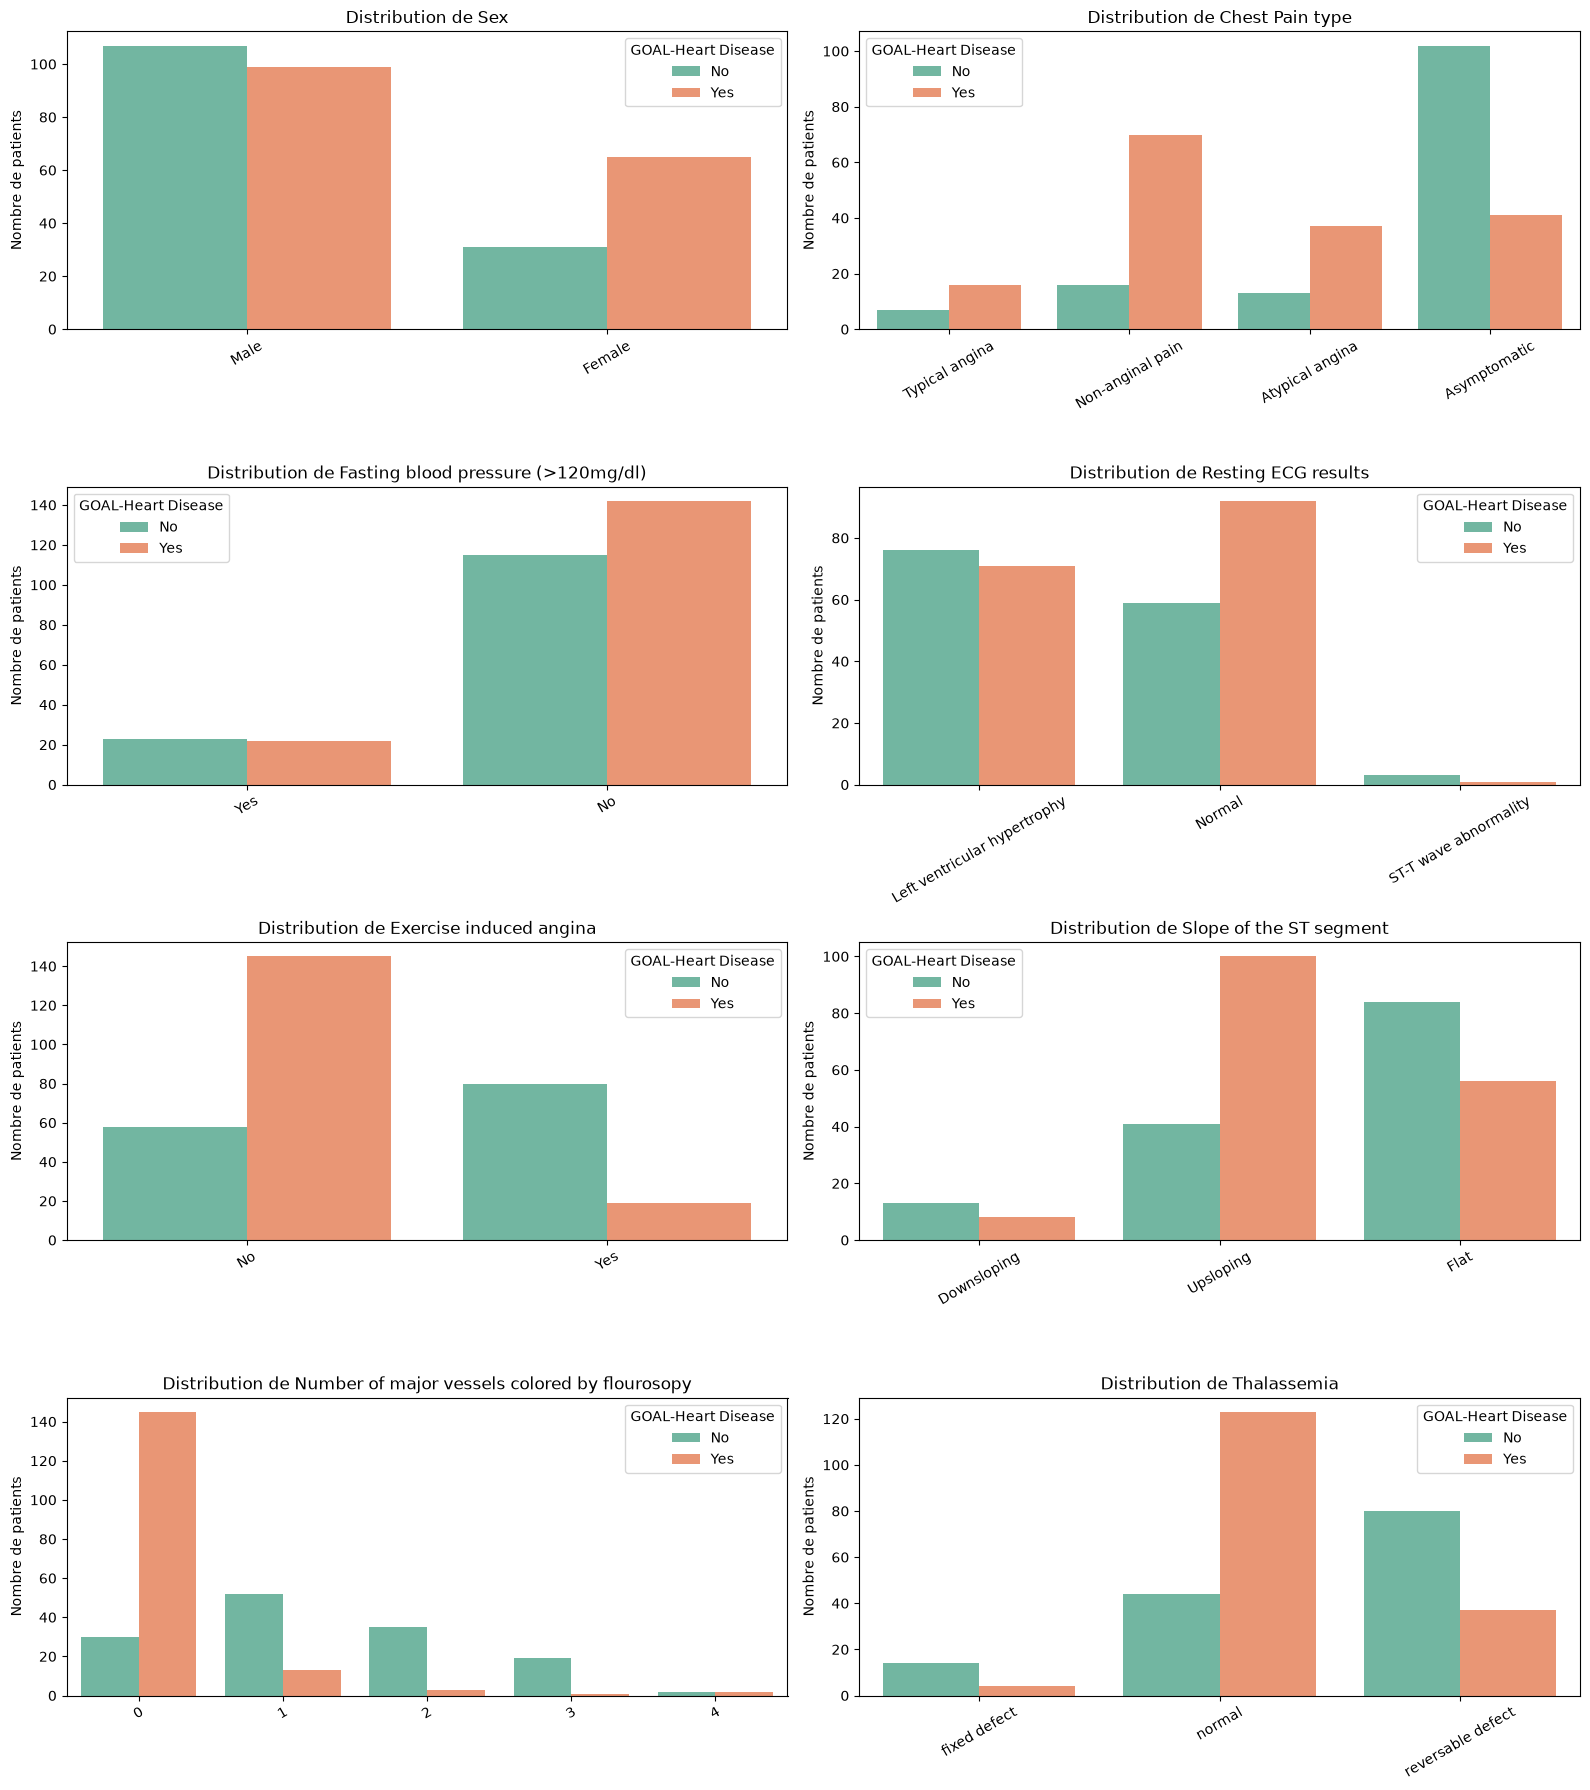

In [37]:
fig, axes = plt.subplots(4, 2, figsize=(16, 18))
axes = axes.flatten()

for i, col in enumerate(variables_discretes):
    sns.countplot(data=data_discrete, x=col, hue=target, hue_order=["No", "Yes"],
        palette="Set2", ax=axes[i]
    )

    axes[i].set_title(f"Distribution de {col}")
    axes[i].set_xlabel("")
    axes[i].set_ylabel("Nombre de patients")
    axes[i].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

L'analyse des distributions croisées présentées sur ces graphiques permet d'identifier les catégories cliniques *(comme certains types de douleurs thoraciques ou l'absence d'angine à l'effort)* où la proportion de patients diagnostiqués positifs *(Yes)* est la plus marquée. Cette exploration visuelle met en lumière des associations statistiques au sein de notre échantillon, sans toutefois permettre de conclure à un lien de cause à effet entre ces paramètres et une maladie cardiovasculaire.

## **IV - Prétraitement des données**

#### 1. Séparation des variables explicatives et de la variable cible

In [38]:
X = data_discrete.drop(columns=[target])
y = data_discrete[target].map({"No": 0, "Yes": 1})

print("Dimensions de X :", X.shape)
print("Dimensions de y :", y.shape)

Dimensions de X : (302, 8)
Dimensions de y : (302,)


#### 2. Split Train/Test

In [39]:
# stratify=y permet de conserver quasiment la proportion de chaque classe dans les deux ensembles. 
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [40]:
print(X_train.shape, X_test.shape, y_train.shape, y_test.shape)

(241, 8) (61, 8) (241,) (61,)


#### 3. Encodage des variables catégorielles

L'algorithme Bernoulli Naive Bayes nécessite des caractéristiques binaires **(0 ou 1)**, ainsi on va utiliser le **One-Hot Encoding**, qui transforme chaque modalité d'une variable catégorielle en une caractéristique binaire.

In [41]:
encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False
)

X_train_encoded = encoder.fit_transform(X_train)
X_test_encoded = encoder.transform(X_test)

print("Dimensions après encodage :", X_train_encoded.shape)

Dimensions après encodage : (241, 24)


## **V – Modélisation**

### 1. Classification avec Bernoulli Naive Bayes

**Principe.** Pour un patient décrit par ses variables $x = (x_1, \dots, x_n)$, le modèle applique le théorème de Bayes et prédit la classe la plus probable :

$$\hat{y} = \arg\max_{y}\; P(y)\prod_{i=1}^{n} P(x_i \mid y)$$

**Hypothèses.**
- *Naïve* : les variables sont supposées indépendantes entre elles sachant la classe. C'est une simplification, mais elle permet d'estimer le modèle avec peu de données (302 patients ici).
- *Bernoulli* : chaque variable est binaire (0/1) et suit une loi de Bernoulli de paramètre $P(x_i = 1 \mid y)$. L'absence d'une caractéristique est donc elle aussi prise en compte.

**Nos données.** Nos variables discrètes ayant plusieurs modalités, c'était tout l'intérêt de les transformer par one-hot encoding pour les rendre binaires.

**Hyperparamètre.** `alpha` est le lissage de Laplace : il évite qu'une modalité absente d'une classe donne une probabilité nulle. On le choisit par validation croisée.

**Avantages / limites.** Modèle rapide et interprétable, adapté aux petits jeux de données, mais il ignore les interactions entre variables. C'est ce que le MLP pourra apprendre, d'où la comparaison.

Meilleur alpha : 3
Meilleur F1-score (validation croisée) : 0.88

**** Performances sur l'ensemble de test ****
Accuracy : 0.885

Rapport de classification :
                precision    recall  f1-score   support

Pas de maladie       0.92      0.82      0.87        28
       Maladie       0.86      0.94      0.90        33

      accuracy                           0.89        61
     macro avg       0.89      0.88      0.88        61
  weighted avg       0.89      0.89      0.88        61



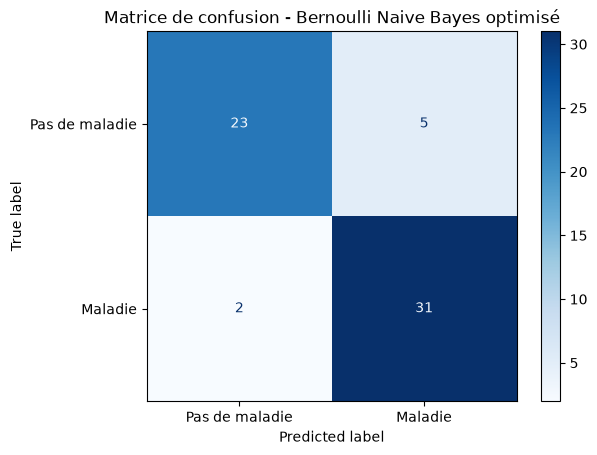

In [42]:
# 1. Recherche du meilleur hyperparamètre alpha
param_grid = {
    "alpha": [0.01, 0.1, 0.5, 1, 2, 3, 5]
}

grid_bnb = GridSearchCV(
    estimator=BernoulliNB(),
    param_grid=param_grid,
    cv=5,
    scoring="f1",
    n_jobs=-1
)

# 2. Entraînement et validation croisée
grid_bnb.fit(X_train_encoded, y_train)

print("Meilleur alpha :", grid_bnb.best_params_["alpha"])
print("Meilleur F1-score (validation croisée) :",
      round(grid_bnb.best_score_, 3))

# 3. Récupération du meilleur modèle
model_bnb = grid_bnb.best_estimator_

# 4. Prédictions sur l'ensemble de test
y_pred_bnb = model_bnb.predict(X_test_encoded)

# 5. Évaluation des performances
print("\n**** Performances sur l'ensemble de test ****")
print("Accuracy :", round(accuracy_score(y_test, y_pred_bnb), 3))

print("\nRapport de classification :")
print(classification_report(
    y_test,
    y_pred_bnb,
    target_names=["Pas de maladie", "Maladie"]
))

# 6. Matrice de confusion
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_bnb,
    display_labels=["Pas de maladie", "Maladie"],
    cmap="Blues"
)

plt.title("Matrice de confusion - Bernoulli Naive Bayes optimisé")
plt.show()

### 2. Classification avec le perceptron multicouche (MLP)

Le MLP est un réseau de neurones artificiels constitué d'une couche d'entrée, d'une ou plusieurs couches cachées et d'une couche de sortie.

Contrairement au Naive Bayes, il peut apprendre des relations non linéaires entre les variables explicatives.

Meilleurs paramètres : {'activation': 'tanh', 'alpha': 0.0001, 'hidden_layer_sizes': (32,)}
Meilleur F1-score (validation croisée) : 0.743

--- Performances sur l'ensemble de test ---
Accuracy : 0.885

Rapport de classification :
                precision    recall  f1-score   support

Pas de maladie       0.96      0.79      0.86        28
       Maladie       0.84      0.97      0.90        33

      accuracy                           0.89        61
     macro avg       0.90      0.88      0.88        61
  weighted avg       0.89      0.89      0.88        61



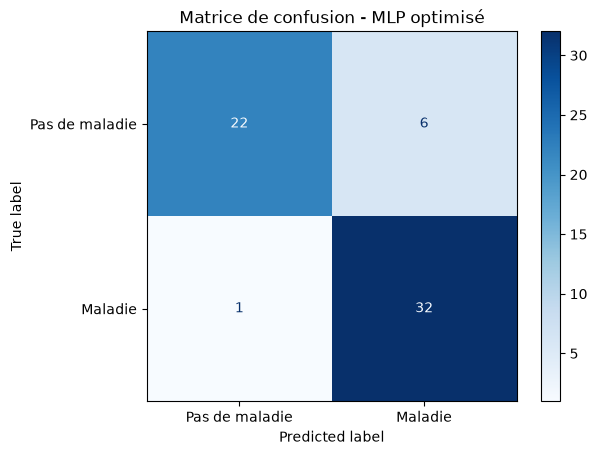

In [43]:
# 1. Définition des hyperparamètres à optimiser
param_grid_mlp = {
    "hidden_layer_sizes": [(8,), (16,), (32,), (16, 8)],
    "alpha": [1e-4, 1e-3, 1e-2, 1e-1],
    "activation": ["relu", "tanh"]
}

# 2. Initialisation du MLP et recherche des meilleurs paramètres
grid_mlp = GridSearchCV(
    estimator=MLPClassifier(
        solver="adam",
        max_iter=2000,
        random_state=42,
        early_stopping=True
    ),
    param_grid=param_grid_mlp,
    cv=5,
    scoring="f1",
    n_jobs=-1
)

# 3. Entraînement avec validation croisée
grid_mlp.fit(X_train_encoded, y_train)

print("Meilleurs paramètres :", grid_mlp.best_params_)
print("Meilleur F1-score (validation croisée) :",
      round(grid_mlp.best_score_, 3))

# 4. Récupération du meilleur modèle
model_mlp = grid_mlp.best_estimator_

# 5. Prédictions sur l'ensemble de test
y_pred_mlp = model_mlp.predict(X_test_encoded)

# 6. Évaluation des performances
print("\n--- Performances sur l'ensemble de test ---")
print("Accuracy :", round(accuracy_score(y_test, y_pred_mlp), 3))

print("\nRapport de classification :")
print(classification_report(
    y_test,
    y_pred_mlp,
    target_names=["Pas de maladie", "Maladie"]
))

# 7. Matrice de confusion
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_mlp,
    display_labels=["Pas de maladie", "Maladie"],
    cmap="Blues"
)

plt.title("Matrice de confusion - MLP optimisé")
plt.show()

## **VI – Comparaison des performances**

In [44]:
# Affichons les métriques des modèles 
resultats = pd.DataFrame({
    "Modèle": ["Bernoulli Naive Bayes", "MLP"],
    "Accuracy": [accuracy_score(y_test, y_pred_bnb), accuracy_score(y_test, y_pred_mlp)],
    "Précision": [precision_score(y_test, y_pred_bnb), precision_score(y_test, y_pred_mlp)],
    "Rappel": [recall_score(y_test, y_pred_bnb), recall_score(y_test, y_pred_mlp)],
    "F1-score": [f1_score(y_test, y_pred_bnb), f1_score(y_test, y_pred_mlp)]
    })

display(resultats.round(3))

,Modèle,Accuracy,Précision,Rappel,F1-score
0,Bernoulli Naive Bayes,0.885,0.861,0.939,0.899
1,MLP,0.885,0.842,0.970,0.901


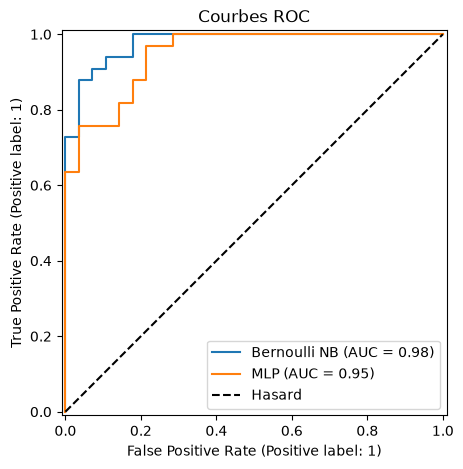

In [45]:
# courbes ROC
from sklearn.metrics import RocCurveDisplay, roc_auc_score

fig, ax = plt.subplots(figsize=(6, 5))
RocCurveDisplay.from_estimator(model_bnb, X_test_encoded, y_test, ax=ax, name="Bernoulli NB")
RocCurveDisplay.from_estimator(model_mlp, X_test_encoded, y_test, ax=ax, name="MLP")
ax.plot([0, 1], [0, 1], "k--", label="Hasard")
ax.legend()
plt.title("Courbes ROC")
plt.show()

#### **Interprétation et comparaison des performances**

Les deux modèles obtiennent une accuracy identique de 88,5 % sur l’ensemble de test, avec des F1-scores très proches (0,899 pour le Bernoulli Naive Bayes et 0,901 pour le MLP). Cette égalité masque un compromis : le MLP présente un rappel supérieur (97,0 % contre 93,9 %) et détecte donc davantage de patients malades, tandis que le Bernoulli Naive Bayes a une meilleure précision (86,1 % contre 84,2 %) et génère moins de faux positifs. Dans les deux cas, l’écart correspond à un seul patient de l’ensemble de test.

Les courbes ROC complètent cette comparaison en évaluant la capacité de discrimination des modèles indépendamment du seuil de classification. Les AUC sont élevées pour les deux modèles (0,98 pour le Bernoulli Naive Bayes et 0,95 pour le MLP), avec un léger avantage pour le premier.

**Ces résultats montrent que le MLP, malgré sa capacité à modéliser des relations non linéaires, n’apporte pas de gain net par rapport au Bernoulli Naive Bayes, plus simple et interprétable. Toutefois, dans un contexte médical où manquer un patient malade est plus grave qu’une fausse alerte, le rappel plus élevé du MLP pourrait justifier sa préférence.**

Ces observations doivent être nuancées : l’ensemble de test ne contient que 61 patients, et les différences observées ne suffisent pas à établir la supériorité d’un modèle. Une validation croisée répétée permettrait de confirmer ces tendances.

## **VII – limites & conclusion**

### 1. Limites de l'étude et perspectives d'amélioration

Malgré les performances encourageantes obtenues, notre étude présente certaines limites qu'il convient de souligner.

- **Taille du jeu de données :** Notre étude repose sur un échantillon relativement restreint de 302 patients, dont seulement 61 constituent l'ensemble de test. Cette taille limitée peut affecter la robustesse de l'évaluation et la capacité de généralisation des modèles. À titre d'exemple, une seule prédiction passant d'incorrecte à correcte entraîne une variation d'environ 1,64 point de pourcentage de l'accuracy. Les résultats doivent donc être interprétés avec prudence.

- **Perte d'information liée à la sélection des variables :** Conformément aux objectifs du projet, nous avons uniquement retenu les variables discrètes, excluant ainsi certaines caractéristiques cliniques potentiellement pertinentes, telles que l'âge, le taux de cholestérol, la fréquence cardiaque maximale ou la dépression du segment ST. Une première perspective d'amélioration consisterait à discrétiser ces variables continues, par exemple en définissant des tranches d'âge ou des intervalles fondés sur des seuils cliniques, afin de les intégrer au classifieur Bernoulli Naive Bayes après un encodage adapté. Une autre approche serait d'entraîner le MLP sur l'ensemble des variables explicatives, en combinant la standardisation des variables continues et l'encodage des variables catégorielles.

Enfin, il serait intéressant d'élargir l'étude à d'autres algorithmes de classification afin de comparer davantage d'approches et d'évaluer si celles-ci permettent d'améliorer les performances prédictives.

### 2. Conclusion

Ce projet visait à prédire la présence d’une maladie cardiovasculaire à partir des seules variables discrètes du jeu de données (302 patients après suppression d’un doublon, 8 variables explicatives, 24 variables binaires après encodage one-hot). Deux classifieurs ont été comparés, un Bernoulli Naive Bayes et un perceptron multicouche (MLP), tous deux optimisés par validation croisée sur l’ensemble d’entraînement.

Sur l’ensemble de test (61 patients), les deux modèles atteignent une accuracy identique de 88,5 %, nettement supérieure à celle d’un classifieur prédisant toujours la classe majoritaire (environ 54 %). Leurs F1-scores sont quasi égaux (0,899 et 0,901). Le MLP détecte plus de patients malades (rappel de 97,0 % contre 93,9 %), mais produit un faux positif de plus (précision de 84,2 % contre 86,1 %). Chaque écart correspond à un seul patient.

Plusieurs éléments penchent en faveur du Bernoulli Naive Bayes : une AUC plus élevée (0,98 contre 0,95), un F1-score en validation croisée nettement supérieur (0,88 contre 0,74), donc des performances plus stables, ainsi qu’une plus grande simplicité et une meilleure interprétabilité. Sur un jeu de données aussi restreint, la capacité du MLP à modéliser des relations non linéaires ne se traduit pas par un gain mesurable.

Le choix final dépend toutefois de l’usage visé. Dans un contexte de dépistage, où manquer un patient malade est plus grave qu’une fausse alerte, le rappel plus élevé du MLP présente un intérêt. Un autre levier serait d’abaisser le seuil de décision du Bernoulli Naive Bayes pour favoriser le rappel. Nous retenons donc le Bernoulli Naive Bayes comme modèle de référence, tout en soulignant que cette préférence reste à confirmer. Le test ne compte que 61 patients et seules les variables discrètes ont été exploitées.

En définitive, ce projet a permis de mettre en œuvre et de comparer deux méthodes de classification, tout en soulignant l'importance du choix des variables, des métriques d'évaluation et de l'interprétation des résultats dans un problème de prédiction médicale.